In [1]:
import torch
import numpy as np
import pandas as pd
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import random
import os

from data_setup import TESSDataset, create_dataloaders

In [2]:
RANDOM_SEED = 42

def set_seed(seed: int = 42):
    """Locks down all random number generators for strict reproducibility."""
    # 1. Set Python random seed
    random.seed(seed)
    
    # 2. Set Python environment seed
    os.environ['PYTHONHASHSEED'] = str(seed)
    
    # 3. Set NumPy seed
    np.random.seed(seed)
    
    # 4. Set PyTorch CPU seed
    torch.manual_seed(seed)
    
    # 5. Set PyTorch Apple Silicon (MPS) seed
    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)
        
    # 6. Set PyTorch CUDA seeds (Standard practice to include for portability)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

In [3]:
# Setup device agnostic
device = "mps" if torch.backends.mps.is_available() else "cpu"
device

'mps'

In [4]:
if device == 'mps':
    torch.mps.manual_seed(RANDOM_SEED)

In [5]:
csv_path = "data/processed_labels.csv"
data_dir = "data/lightcurves"

BATCH_SIZE = 32

In [6]:
train_dataloader, test_dataloader = create_dataloaders(
    csv_path = csv_path,
    data_dir = data_dir,
    batch_size = BATCH_SIZE
)

train_dataloader, test_dataloader

Dataset initialized with 1816 strictly synced samples.
Dataset initialized with 454 strictly synced samples.


(<torch.utils.data.dataloader.DataLoader at 0x114cb80e0>,
 <torch.utils.data.dataloader.DataLoader at 0x114cb8110>)

In [7]:
def accuracy_fn(y_true, y_pred):
    y_pred_rounded = torch.round(y_pred)
    
    y_true_int = y_true.cpu().int()
    y_pred_int = y_pred_rounded.cpu().int()
    
    correct = torch.eq(y_true_int, y_pred_int).sum().item() 
    
    acc = (correct / len(y_pred)) * 100 
    return acc

Dataset initialized with 1816 strictly synced samples.


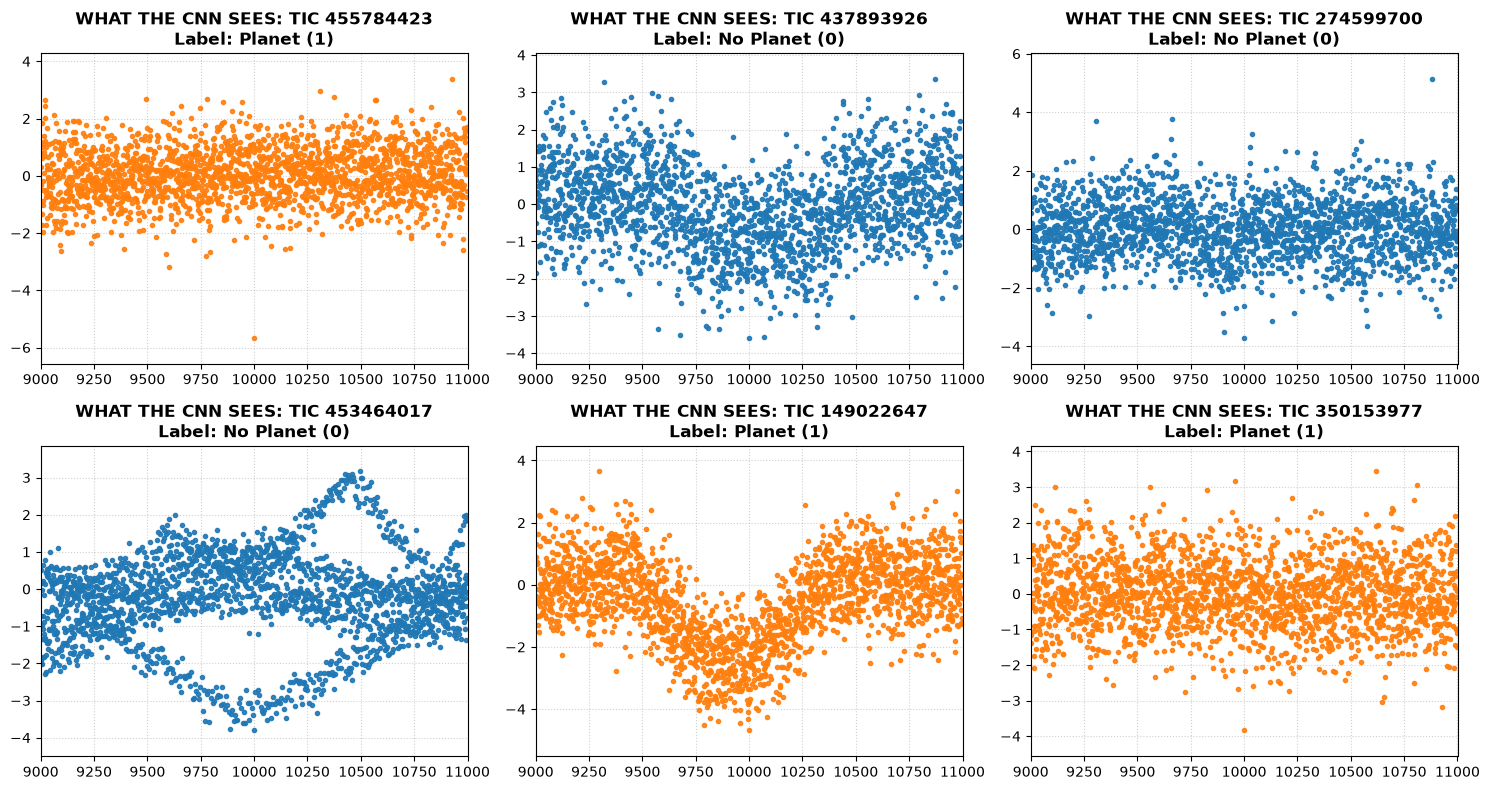

In [20]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader

debug_dataset = TESSDataset(
    labels_df = train_dataloader.dataset.labels_df,
    lightcurves_dir = data_dir,
    transform = None,      # no shift/noise while inspecting — see raw phase-folded shape
    return_id = True
)
debug_loader = DataLoader(debug_dataset, batch_size = 6, shuffle = True)

X_batch, y_batch, tic_batch = next(iter(debug_loader))

# 2. Apply your global Z-Score Normalization
mean = X_batch.mean(dim = 2, keepdim = True)
std = X_batch.std(dim = 2, keepdim = True)
X_batch = (X_batch - mean) / (std + 1e-8)

# Slice exactly what your model's focused branch sees
X_focused = X_batch[:, :, 9000:11000]

X_vis, y_vis, tic_vis = X_focused.numpy(), y_batch.numpy(), tic_batch.numpy()

# Create an X-axis array for physical alignment
x_axis = np.arange(9000, 11000)

fig, axes = plt.subplots(2, 3, figsize = (15, 8))
axes = axes.flatten()

for i in range(6):
    lightcurve = X_vis[i].squeeze()
    label = int(y_vis[i].item())
    tic_id = int(tic_vis[i])

    color = '#ff7f0e' if label == 1 else '#1f77b4'
    
    axes[i].plot(x_axis, lightcurve, color = color, alpha = 0.9, linewidth = 0, marker = '.')
    axes[i].set_title(f"WHAT THE CNN SEES: TIC {tic_id}\nLabel: {'Planet (1)' if label else 'No Planet (0)'}", fontweight = 'bold')
    
    # Dynamically scale the Y-axis based strictly on the focused window
    y_min, y_max = lightcurve.min(), lightcurve.max()
    padding = (y_max - y_min) * 0.1
    if padding == 0:
        padding = 0.5
        
    axes[i].set_ylim(y_min - padding, y_max + padding)
    axes[i].set_xlim(9000, 11000)
    axes[i].grid(True, linestyle = ':', alpha = 0.6)

plt.tight_layout()
plt.show()

In [18]:
import numpy as np
import pandas as pd
from pathlib import Path

labels_df = pd.read_csv("data/processed_labels.csv")
data_dir = Path("data/lightcurves")

FOCUS_START, FOCUS_END = 9000, 11000
FOCUS_CENTER = (FOCUS_START + FOCUS_END) // 2   # 10000 — array center post-centering
TRANSIT_HALF_WIDTH = 75   # ~150-pt band, per the "50-150 step" transit width noted in your V5 model comments — tune as needed

rows = []
for _, row in labels_df.iterrows():
    tic_id = int(row["TIC_ID"])
    label = row["final_label"]  # <-- confirm this matches the column name your own audit script used

    fpath = data_dir / f"TIC_{tic_id}.npy"
    if not fpath.exists():
        continue

    flux = np.load(fpath).astype(np.float64)

    # Same per-sample global z-score normalization as the training loop
    mean = flux.mean()
    std = flux.std()
    flux_norm = (flux - mean) / (std + 1e-8)

    focused = flux_norm[FOCUS_START:FOCUS_END]
    local_center = FOCUS_CENTER - FOCUS_START  # 1000, center within the focused slice

    in_transit = focused[local_center - TRANSIT_HALF_WIDTH : local_center + TRANSIT_HALF_WIDTH]
    out_transit = np.concatenate([
        focused[: local_center - TRANSIT_HALF_WIDTH],
        focused[local_center + TRANSIT_HALF_WIDTH :]
    ])

    in_mean = in_transit.mean()
    out_mean = out_transit.mean()
    out_std = out_transit.std()

    # Positive = a real dip relative to the local out-of-transit noise floor
    snr = (out_mean - in_mean) / (out_std + 1e-8)

    rows.append({
        "tic_id": tic_id,
        "label": label,
        "snr": snr,
    })

snr_df = pd.DataFrame(rows)

planets = snr_df[snr_df["label"] == 1].sort_values("snr")
no_planets = snr_df[snr_df["label"] == 0]

print(f"Planet-labeled SNR — median: {planets['snr'].median():.3f}, "
      f"5th pct: {planets['snr'].quantile(0.05):.3f}")
print(f"No-planet SNR (reference) — median: {no_planets['snr'].median():.3f}")

print("\nWeakest 20 'Planet' examples by SNR proxy:")
print(planets.head(20)[["tic_id", "snr"]])

print("\nThe two flagged targets, for calibration:")
print(snr_df[snr_df["tic_id"].isin([153896150, 264171144])])

Planet-labeled SNR — median: 0.222, 5th pct: -0.074
No-planet SNR (reference) — median: 0.141

Weakest 20 'Planet' examples by SNR proxy:
         tic_id       snr
1361  438260486 -0.146430
1253  422618449 -0.142628
976   335952150 -0.140666
1716   31786438 -0.137452
1915  310266243 -0.135755
0      50120414 -0.134957
768   141074654 -0.130744
879   431810418 -0.129157
637   324150445 -0.127717
2205  114947483 -0.126194
602   236934268 -0.124784
441   453060368 -0.124690
614   141770198 -0.123959
1558  125563127 -0.123064
1248  267650535 -0.119521
2124  199721945 -0.119173
1556  435878153 -0.119115
178   303686889 -0.118036
1297  441804533 -0.116273
758   322593401 -0.113469

The two flagged targets, for calibration:
         tic_id  label       snr
607   264171144    1.0 -0.016934
1791  153896150    1.0 -0.041064


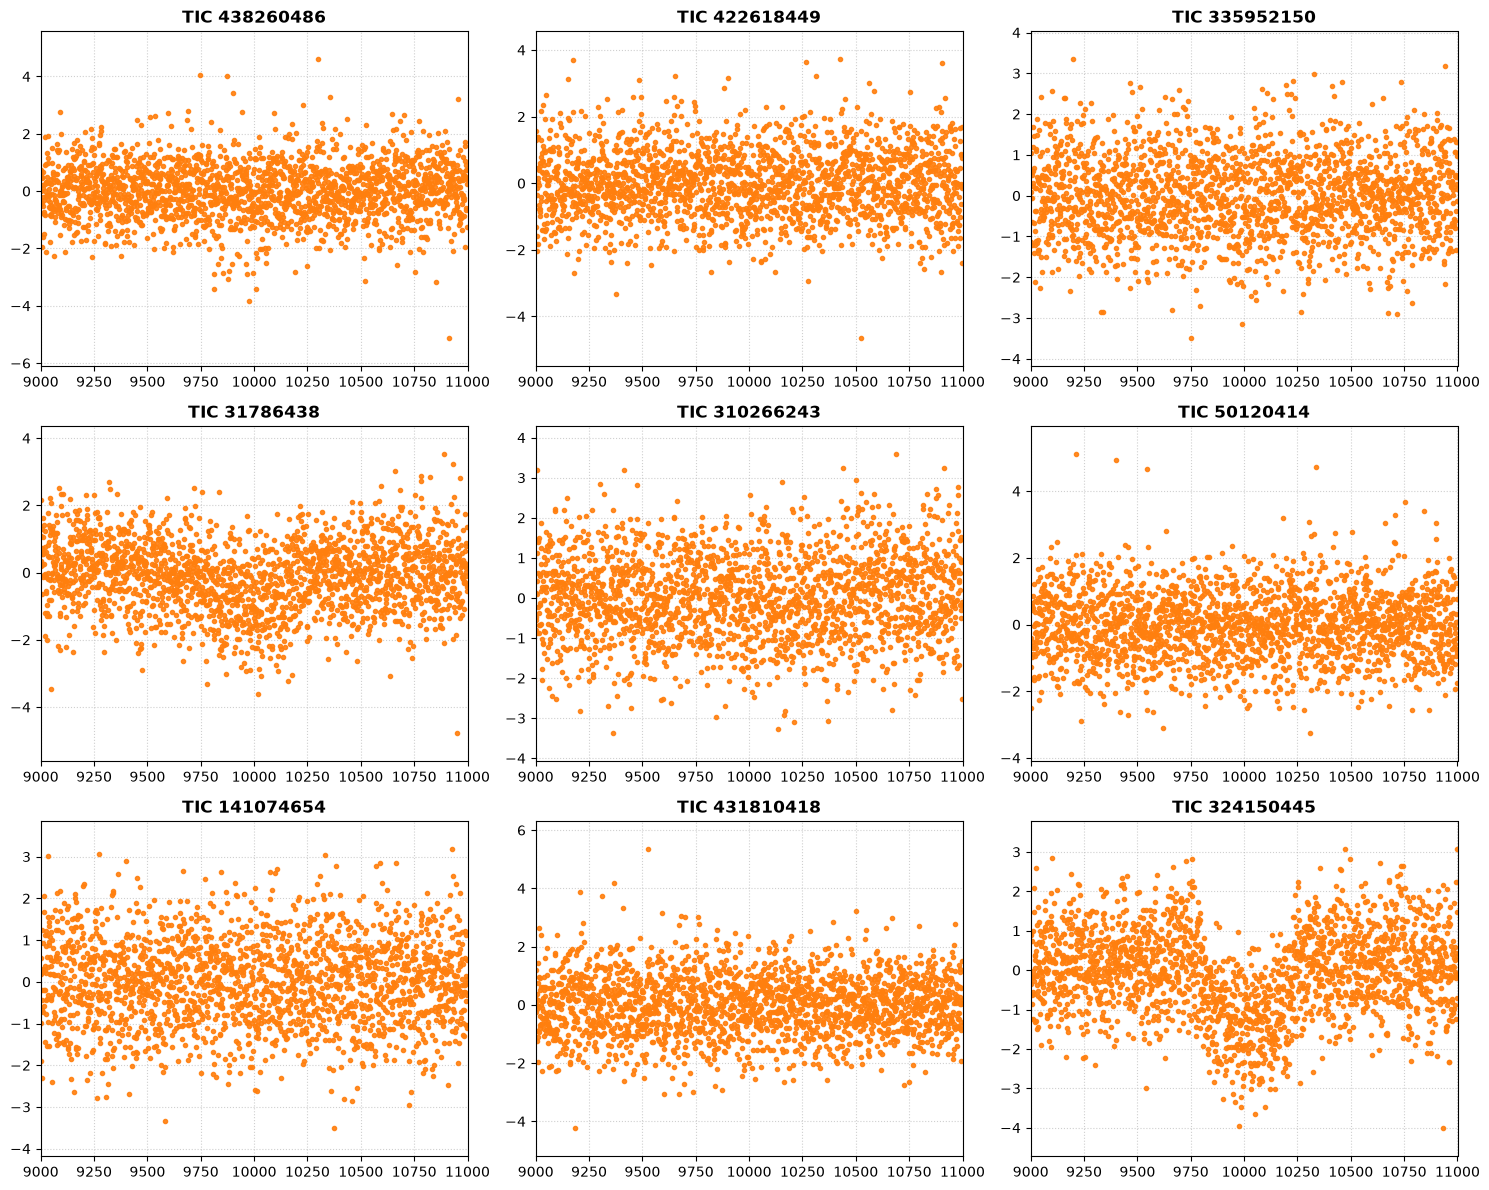

In [29]:
new_weakest = [438260486, 422618449, 335952150, 31786438, 310266243, 50120414,
               141074654, 431810418, 324150445, 114947483, 236934268, 453060368,
               141770198, 125563127, 267650535, 199721945, 435878153, 303686889,
               441804533, 322593401]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, tic_id in enumerate(new_weakest[:9]):
    flux = np.load(Path("data/lightcurves_v2") / f"TIC_{tic_id}.npy").astype(np.float64)
    mean, std = flux.mean(), flux.std()
    focused = ((flux - mean) / (std + 1e-8))[9000:11000]
    x_axis = np.arange(9000, 11000)

    axes[i].plot(x_axis, focused, color='#ff7f0e', alpha=0.9, linewidth=0, marker='.')
    axes[i].set_title(f"TIC {tic_id}", fontweight='bold')
    y_min, y_max = focused.min(), focused.max()
    pad = (y_max - y_min) * 0.1 or 0.5
    axes[i].set_ylim(y_min - pad, y_max + pad)
    axes[i].set_xlim(9000, 11000)
    axes[i].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

In [21]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class TESSModelV5(nn.Module):
    def __init__(self):
        super().__init__()

        # Wide-angle lens: Massive kernel to see the macro shape of the lightcurve
        # Final output length hitting the pool branch: 156 (156 / 4 = 39, perfectly divisible)
        self.global_view = nn.Sequential(
            nn.Conv1d(
                in_channels = 1,
                out_channels = 16,
                kernel_size = 61,
                stride = 4,
                #padding = 30
            ),
            nn.BatchNorm1d(16),
            nn.LeakyReLU(0.1),
            nn.Dropout1d(p = 0.2),
            nn.MaxPool1d(kernel_size = 4),
            nn.Conv1d(
                in_channels = 16,
                out_channels = 32,
                kernel_size = 31,
                stride = 2,
                padding = 15
            ),
            nn.BatchNorm1d(32),
            nn.LeakyReLU(0.1),
            nn.Dropout1d(p = 0.2),
            nn.MaxPool1d(kernel_size = 4)
        )

        # Portrait lens: Medium kernel tailored to the 50-150 step width of a transit
        # Final output length hitting the pool branch: 248 (248 / 4 = 62, perfectly divisible)
        self.focused_view = nn.Sequential(
            nn.Conv1d(
                in_channels = 1,
                out_channels = 16,
                kernel_size = 5,
                stride = 2,
                #padding = 10
            ),
            nn.BatchNorm1d(16),
            nn.LeakyReLU(0.1),
            nn.Dropout1d(p = 0.2),
            nn.MaxPool1d(kernel_size = 2),
            nn.Conv1d(
                in_channels = 16,
                out_channels = 32,
                kernel_size = 5,
                stride = 1,
                #padding = 3
            ), 
            nn.BatchNorm1d(32),
            nn.LeakyReLU(0.1),
            nn.Dropout1d(p = 0.2),
            nn.MaxPool1d(kernel_size = 2)
        )

        # Classifier input size remains perfectly matched at 512 features
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features = 128, out_features = 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(0.1),
            nn.Dropout(p = 0.5), 
            nn.Linear(in_features = 128, out_features = 1)
        )

    def pool_branch(self, feat):
        avg = F.adaptive_avg_pool1d(feat, 1).squeeze(-1)
        mn = -F.adaptive_max_pool1d(-feat, 1).squeeze(-1)
        return torch.cat([avg, mn], dim = 1)
        
    def forward(self, x):
        x_focused = x[:, :, 9000:11000]

        global_output = self.global_view(x)
        focused_output = self.focused_view(x_focused)

        global_summary  = self.pool_branch(global_output)
        focused_summary = self.pool_branch(focused_output)
        
        merge_views = torch.cat([global_summary, focused_summary], dim = 1)

        return self.classifier(merge_views)

In [22]:
model_5 = TESSModelV5().to(device)
model_5

TESSModelV5(
  (global_view): Sequential(
    (0): Conv1d(1, 16, kernel_size=(61,), stride=(4,))
    (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.1)
    (3): Dropout1d(p=0.2, inplace=False)
    (4): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
    (5): Conv1d(16, 32, kernel_size=(31,), stride=(2,), padding=(15,))
    (6): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): LeakyReLU(negative_slope=0.1)
    (8): Dropout1d(p=0.2, inplace=False)
    (9): MaxPool1d(kernel_size=4, stride=4, padding=0, dilation=1, ceil_mode=False)
  )
  (focused_view): Sequential(
    (0): Conv1d(1, 16, kernel_size=(5,), stride=(2,))
    (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): LeakyReLU(negative_slope=0.1)
    (3): Dropout1d(p=0.2, inplace=False)
    (4): MaxPool1d(kernel_size=2, st

In [23]:
set_seed(42)

import torch
import torch.optim as optim
import copy

#loss_fn = FocalLoss(alpha = 0.75, gamma = 2.0)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model_5.parameters(), lr = 0.001, weight_decay = 1e-4) ##

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, 
    mode = 'min', 
    factor = 0.5, 
    patience = 5
)

epochs = 100

# Additional var to capture the best model state
best_test_loss = float('inf') # Initializing to inf so that the first loss value starts the process
best_model_weights = None
best_epoch = 0

for epoch in range(epochs):
    ### TRAINING
    model_5.train() ##
    train_loss, train_accuracy = 0, 0
    
    for X, y in train_dataloader:
        X, y = X.to(device), y.to(device)

        # Z-Score Normalization
        mean = X.mean(dim = 2, keepdim = True)
        std = X.std(dim = 2, keepdim = True)
        X = (X - mean) / (std + 1e-8)
        
        """
        X = X - 1.0
        X = torch.clamp(X, min = -0.1, max = 0.1)
        X = X * 10.0
        """
        
        y = y.float().unsqueeze(dim = 1)
        
        y_pred = model_5(X) ##
        
        loss = loss_fn(y_pred, y)
        train_loss += loss.item()

        y_pred_probs = torch.sigmoid(y_pred)
        train_accuracy += accuracy_fn(y_true = y, y_pred = y_pred_probs)
        
        optimizer.zero_grad()
        
        loss.backward()
        
        optimizer.step()
        
    train_loss /= len(train_dataloader)
    train_accuracy /= len(train_dataloader)
    
    ### TESTING
    model_5.eval() ##
    test_loss, test_accuracy = 0, 0
    
    with torch.inference_mode():
        for X_test, y_test in test_dataloader:
            X_test, y_test = X_test.to(device), y_test.to(device)

            mean = X_test.mean(dim = 2, keepdim = True)
            std = X_test.std(dim = 2, keepdim = True)
            X_test = (X_test - mean) / (std + 1e-8)
            
            """
            X_test = X_test - 1.0
            X_test = torch.clamp(X_test, min = -0.1, max = 0.1)
            X_test = X_test * 10.0
            """

            y_test = y_test.float().unsqueeze(dim = 1)
            
            test_pred = model_5(X_test) ##
            
            loss = loss_fn(test_pred, y_test)
            test_loss += loss.item()

            test_pred_probs = torch.sigmoid(test_pred)
            test_accuracy += accuracy_fn(y_true = y_test, y_pred = test_pred_probs)
            
        test_loss /= len(test_dataloader)
        test_accuracy /= len(test_dataloader)

    scheduler.step(test_loss)
    current_lr = optimizer.param_groups[0]['lr']
        
    # Checkpointing implementation
    if test_loss < best_test_loss:
        best_test_loss = test_loss
        best_epoch = epoch
        
        # Copying weights to memory using copy.deepcopy to prevent them being overwritten
        best_model_weights = copy.deepcopy(model_5.state_dict()) ##
        checkpoint_msg = "|Saved|"
        
    else:
        checkpoint_msg = ""
        
    # Print
    if (epoch + 1) % 5 == 0 or checkpoint_msg:
        print(f"Epoch {epoch} | LR: {current_lr:.8f} | Train Loss: {train_loss:.4f} Accuracy: {train_accuracy:.2f}% | Test Loss: {test_loss:.4f} Accuracy: {test_accuracy:.2f}% {checkpoint_msg}")

# Load the captured best state of the model
print(f"Best state captured at Epoch: {best_epoch}, test loss: {best_test_loss:.4f}")

# Overwrite model with captured best state
model_5.load_state_dict(best_model_weights) ##


Epoch 0 | LR: 0.00100000 | Train Loss: 0.7199 Accuracy: 50.42% | Test Loss: 0.6885 Accuracy: 52.71% |Saved|
Epoch 2 | LR: 0.00100000 | Train Loss: 0.7057 Accuracy: 51.79% | Test Loss: 0.6847 Accuracy: 59.58% |Saved|
Epoch 3 | LR: 0.00100000 | Train Loss: 0.6978 Accuracy: 52.67% | Test Loss: 0.6798 Accuracy: 61.81% |Saved|
Epoch 4 | LR: 0.00100000 | Train Loss: 0.6961 Accuracy: 52.76% | Test Loss: 0.6778 Accuracy: 62.15% |Saved|
Epoch 5 | LR: 0.00100000 | Train Loss: 0.6916 Accuracy: 53.69% | Test Loss: 0.6756 Accuracy: 59.44% |Saved|
Epoch 8 | LR: 0.00100000 | Train Loss: 0.6878 Accuracy: 52.65% | Test Loss: 0.6746 Accuracy: 56.88% |Saved|
Epoch 9 | LR: 0.00100000 | Train Loss: 0.6810 Accuracy: 55.45% | Test Loss: 0.6683 Accuracy: 64.51% |Saved|
Epoch 11 | LR: 0.00100000 | Train Loss: 0.6875 Accuracy: 54.29% | Test Loss: 0.6658 Accuracy: 63.33% |Saved|
Epoch 12 | LR: 0.00100000 | Train Loss: 0.6808 Accuracy: 55.81% | Test Loss: 0.6623 Accuracy: 60.62% |Saved|
Epoch 13 | LR: 0.00100000 

<All keys matched successfully>

Optimal threshold: 0.489
               precision    recall  f1-score   support

No Planet (0)       0.73      0.56      0.64       218
   Planet (1)       0.67      0.81      0.73       236

     accuracy                           0.69       454
    macro avg       0.70      0.69      0.68       454
 weighted avg       0.70      0.69      0.69       454



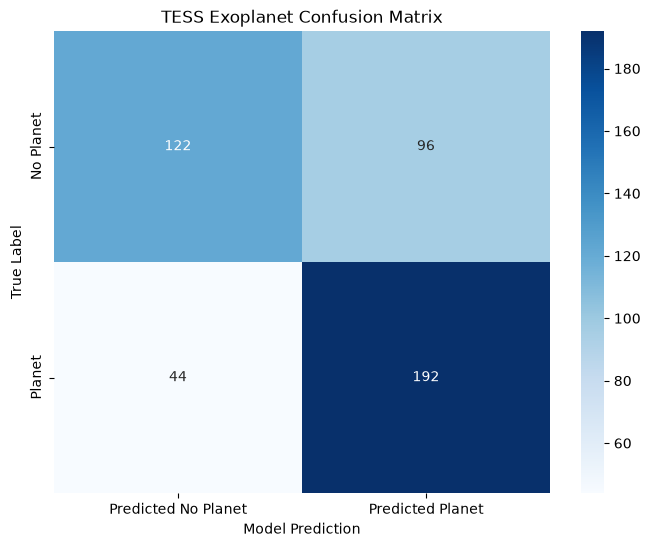

In [24]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report, roc_curve

model_5.eval() ##

all_preds = []
all_true = []
all_probs = []
all_raw_flux = []

# re-run the confusion matrix using this threshold instead of a fixed 0.50
#b_preds_recalibrated = (np.array(all_probs) >= thresholds[best_idx]).astype(int)

#confidence = 0.516 # Tried different values in the range [0.35, 0.65]

with torch.inference_mode():
    for X_test, y_test in test_dataloader:
        X_test = X_test.to(device)

        all_raw_flux.append(X_test.cpu())

        mean = X_test.mean(dim = 2, keepdim = True)
        std = X_test.std(dim = 2, keepdim = True)
        X_test = (X_test - mean) / (std + 1e-8)
        
        """
        X_test = X_test - 1.0
        X_test = torch.clamp(X_test, min = -0.1, max = 0.1)
        X_test = X_test * 10.0
        """
        
        test_logits = model_5(X_test) ##
        test_probs = torch.sigmoid(test_logits).squeeze().cpu().numpy() 

        # Convert to binary predictions- 1 or 0
        #b_preds = (test_probs >= confidence).astype(int)

        if test_probs.ndim == 0:
            all_probs.append(test_probs)
            #b_preds = [b_preds]
        else:
            all_probs.extend(test_probs)
        
        #all_preds.extend(b_preds)
        
        # Squeeze y_test to guarantee it is a flat 1D array before extending
        all_true.extend(y_test.squeeze().cpu().numpy())

# Convert lists to numpy arrays for sklearn
all_true = np.array(all_true)
all_preds = np.array(all_preds)
X_test_raw = torch.cat(all_raw_flux)


fpr, tpr, thresholds = roc_curve(all_true, all_probs)
youden_j = tpr - fpr
best_idx = np.argmax(youden_j)
opt_threshold = thresholds[best_idx]
print(f"Optimal threshold: {opt_threshold:.3f}")

# re-run the confusion matrix using this threshold instead of a fixed 0.50
all_preds = (all_probs >= opt_threshold).astype(int)


# Create report
print(classification_report(all_true, all_preds, target_names = ['No Planet (0)', 'Planet (1)']))

# Cretae confusion matrix
cm = confusion_matrix(all_true, all_preds)

plt.figure(figsize = (8, 6))
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues', 
            xticklabels = ['Predicted No Planet', 'Predicted Planet'],
            yticklabels = ['No Planet', 'Planet'])

plt.title("TESS Exoplanet Confusion Matrix")
plt.ylabel("True Label")
plt.xlabel("Model Prediction")
plt.show()

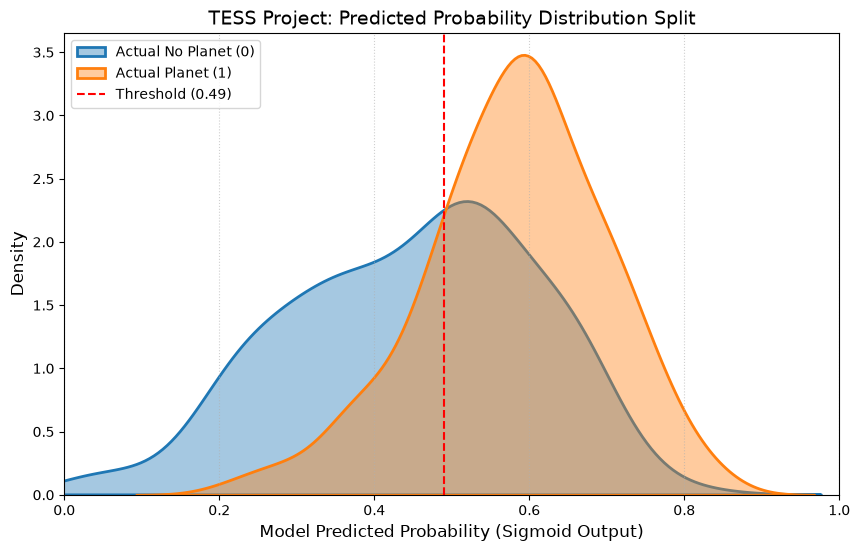

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Ensure arrays are numpy formats
probs_arr = np.array(all_probs)
true_arr = np.array(all_true)

plt.figure(figsize=(10, 6))

# Plot KDE for Negative Class (No Planet)
sns.kdeplot(
    probs_arr[true_arr == 0], 
    label = 'Actual No Planet (0)', 
    fill = True, 
    alpha = 0.4,
    linewidth = 2
)

# Plot KDE for Positive Class (Planet)
sns.kdeplot(
    probs_arr[true_arr == 1], 
    label = 'Actual Planet (1)', 
    fill = True, 
    alpha = 0.4,
    linewidth = 2
)

# Draw the current decision threshold line
plt.axvline(x = opt_threshold, color = 'red', linestyle = '--', label = f'Threshold ({opt_threshold:.2f})')

plt.title('TESS Project: Predicted Probability Distribution Split', fontsize = 14)
plt.xlabel('Model Predicted Probability (Sigmoid Output)', fontsize = 12)
plt.ylabel('Density', fontsize = 12)
plt.xlim(0, 1)
plt.legend(loc = 'upper left')
plt.grid(axis = 'x', linestyle = ':', alpha = 0.6)
plt.show()

In [26]:
# compute depth from raw (untransformed) flux for each test sample, then bucket
depths = 1.0 - X_test_raw.amin(dim=2).squeeze().cpu().numpy()  # before the -1/clamp/*10 transform
shallow_mask = (true_arr == 1) & (depths < 0.01)
deep_mask    = (true_arr == 1) & (depths >= 0.03)

print("Shallow planets — mean predicted prob:", probs_arr[shallow_mask].mean())
print("Deep planets — mean predicted prob:", probs_arr[deep_mask].mean())

Shallow planets — mean predicted prob: 0.56468374
Deep planets — mean predicted prob: 0.5719552


In [27]:
shallow_np_mask = (true_arr == 0) & (depths < 0.01)
deep_np_mask    = (true_arr == 0) & (depths >= 0.03)

print("Shallow No-Planet — mean predicted prob:", probs_arr[shallow_np_mask].mean())
print("Deep No-Planet — mean predicted prob:", probs_arr[deep_np_mask].mean())

Shallow No-Planet — mean predicted prob: 0.45707285
Deep No-Planet — mean predicted prob: 0.37440687
